# Analisis de las velocidades radiales de LHS 1140 (salida de LBL)

Lee **resultados_LBL/completa/RV_LHS1140.csv** (una fila por espectro, salida del notebook de LBL) y hace:

- **Promedio por noche** (ponderado por los errores).
- **Periodograma GLS** con umbrales de falsa alarma (bootstrap) y funcion de ventana.
- **Ajuste de dos sinusoides** en los periodos de la literatura (b y c) y periodograma de los residuos.
- **Sensibilidad al corte de S/N**: repite lo anterior con distintos cortes.
- **Indicadores de actividad** (CRX, DLW...) y BERV: ¿aparecen ahi los picos de periodo largo?
- **Residuos**: umbral de falsa alarma tras quitar b y c, y prueba de un posible tercer periodo (¿es coherente entre temporadas?).
- **Descorrelacion**: quita de los residuos la parte ligada a indicadores de forma de linea (d2v, dW, fwhm) y mira que picos sobreviven.
- **Comparacion con la literatura**: los K de b y c y el periodo/amplitud del exceso frente a los valores publicados (Tabla 1 y Tabla D2 de Cadieux et al. 2024, arXiv:2310.15490).
- **Prueba de cromaticidad** (Cadieux et al. 2024, Apendice D.3): K por banda de longitud de onda; una senal planetaria debe ser acromatica y coherente.
- **Curvas de RV plegadas** de b y c.

Corre las celdas en orden. Todo se guarda en **resultados_LBL/completa/analisis/**.

**Resultados principales:** K_b = 4.78 +- 0.45 m/s y K_c = 2.47 +- 0.47 m/s. Los residuos tienen un exceso a 134.3 d (K = 2.60 +- 0.40 m/s, delta BIC = 22.5), cerca del periodo de rotacion (131 d), con pendiente cromatica de +1.20 +- 0.47 (2.5 sigma).

**Limitaciones:**
- Los espectros se reducen con un solo blaze para todas las epocas, el del taller de COSMIA-UdeA (ver la seccion Blaze del notebook de LBL). La plantilla de LBL se construye con los propios espectros de LHS 1140.
- K_b sale unos 2 sigma por encima de la literatura (3.80 +- 0.11 m/s, Cadieux et al. 2024). El exceso a 134 d, cercano a la rotacion, puede inflarlo.
- d2v, dW y fwhm tienen correlacion 1.0 en la tabla de LBL: cuentan como un solo indicador, no como tres independientes (ver el diagnostico en la seccion Indicadores de actividad y BERV).
- El bootstrap de falsa alarma supone ruido blanco; con ruido correlacionado (actividad) subestima la FAP.

**Orden entre notebooks:** este va despues del notebook de LBL (necesita RV_LHS1140.csv y la tabla .rdb en Drive). Sus resultados (K de b y c) se usan en el notebook de transitos. Dentro de este notebook las celdas dependen unas de otras (promedio por noche, periodograma, ajuste, residuos): corre todas de arriba hacia abajo, sin saltarte ninguna.

## Librerias y datos

### Importamos librerias

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive

### Letra grande para las figuras
Funcion que agranda las etiquetas de los ejes, los numeros y las leyendas de una figura para que se lean bien en el articulo.

In [2]:
def letra_grande(fig, tam_etiqueta=14, tam_numeros=12, tam_leyenda=12):
    # etiquetas, numeros de los ejes y leyendas mas grandes, para el articulo
    for eje in fig.axes:
        eje.xaxis.label.set_size(tam_etiqueta)
        eje.yaxis.label.set_size(tam_etiqueta)
        eje.tick_params(labelsize=tam_numeros)
        leyenda = eje.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(tam_leyenda)

### Constantes del sistema

Valores de LHS 1140 tomados de Cadieux et al. (2024). Es el mismo bloque en los notebooks de RV, transitos y zona habitable.

In [3]:
# constantes de LHS 1140: Cadieux et al. (2024), arXiv:2310.15490. Mismo bloque en los notebooks de RV, transitos y zona habitable
P_ORB = {"b": 24.73723, "c": 3.777940} # d, periodo orbital (Tabla D1)
T0_BTJD = {"b": 1399.9300, "c": 1389.2939} # BJD - 2457000, tiempo de transito (Tabla D1)
M_STAR = 0.1844 # M_sol (Tabla C1)
M_STAR_ERR = 0.0045
R_STAR = 0.2159 # R_sol (Tabla C1)
R_STAR_ERR = 0.0030
TEFF_STAR = 3096.0 # K (Tabla C1)
P_ROT = 131.0 # d, periodo de rotacion (Tabla C1)

### Parametros y datos
Se monta Drive, se fijan las rutas y los parametros del analisis (corte de S/N, remuestreos del bootstrap y rango de periodos) y se lee el CSV de LBL.

In [4]:
drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive/LHS1140_HARPS")
CSV = DRIVE / "resultados_LBL" / "completa" / "RV_LHS1140.csv"
OUT = DRIVE / "resultados_LBL" / "completa" / "analisis"
OUT.mkdir(parents=True, exist_ok=True)

SNR_MIN = 0 # corte de S/N del analisis principal (0 = todos los espectros)
P_PLANETAS = {"c": P_ORB["c"], "b": P_ORB["b"]} # dias (del bloque de constantes)
N_BOOT = 500 # remuestreos para el umbral de falsa alarma (mas = mas lento)
P_MIN, P_MAX = 1.5, 1000.0 # rango de periodos del periodograma (dias)

rv = pd.read_csv(CSV).sort_values("bjd").reset_index(drop=True)
rv = rv[rv.snr47 >= SNR_MIN].copy()
print(len(rv), "espectros | S/N47 de", round(rv.snr47.min(), 1), "a", round(rv.snr47.max(), 1))
print("Primera y ultima fecha:", pd.to_datetime(rv.bjd.min() - 2440587.5, unit="D").date(), "a", pd.to_datetime(rv.bjd.max() - 2440587.5, unit="D").date())

Mounted at /content/drive
293 espectros | S/N47 de 5.6 a 17.5
Primera y ultima fecha: 2015-11-23 a 2019-12-06


## Herramientas

Funciones del analisis: promedio por noche, periodograma GLS, funcion de ventana y ajuste de sinusoides. Se definen aqui para usarlas en las celdas de abajo.

In [5]:
def promedio_por_noche(d):
    # JD cambia a mediodia UT (de dia en Chile): floor(BJD) identifica una noche de observacion
    d = d.assign(noche=np.floor(d.bjd).astype(int))
    filas = []
    for noche, g in d.groupby("noche"):
        w = 1 / g.svrad**2
        filas.append(dict(noche=noche, bjd=np.sum(w * g.bjd) / np.sum(w),
                          vrad=np.sum(w * g.vrad) / np.sum(w),
                          svrad=1 / np.sqrt(np.sum(w)),
                          n=len(g), snr47=g.snr47.mean()))
    return pd.DataFrame(filas)

### GLS
Periodograma Lomb-Scargle generalizado con media flotante (Zechmeister y Kurster 2009), calculado por bloques de frecuencias

In [6]:
def gls(t, y, dy, freq, chunk=2000):
    # GLS con media flotante (Zechmeister & Kurster 2009); potencia normalizada entre 0 y 1
    w = 1 / dy**2
    w = w / w.sum()
    yc = y - np.sum(w * y)
    YY = np.sum(w * yc**2)
    p = np.empty(len(freq))
    for i in range(0, len(freq), chunk):
        f = freq[i:i + chunk]
        arg = 2 * np.pi * np.outer(f, t)
        c, s = np.cos(arg), np.sin(arg)
        C, S = c @ w, s @ w
        YC, YS = c @ (w * yc), s @ (w * yc)
        CC, SS, CS = (c * c) @ w - C * C, (s * s) @ w - S * S, (c * s) @ w - C * S
        D = CC * SS - CS**2
        p[i:i + chunk] = (SS * YC**2 + CC * YS**2 - 2 * CS * YC * YS) / (YY * D)
    return p

### Umbral de falsa alarma
Se barajan las velocidades entre las fechas y se guarda la potencia maxima del GLS. Repitiendo n veces, el cuantil de esos maximos da el umbral

In [7]:
def fap_bootstrap(t, y, dy, freq, n=500, niveles=(0.01, 0.001), seed=1):
    # umbral = cuantil de la potencia maxima al barajar las velocidades entre las fechas
    rng = np.random.default_rng(seed)
    maximos = np.empty(n)
    for k in range(n):
        orden = rng.permutation(len(y))
        maximos[k] = gls(t, y[orden], dy[orden], freq).max()
    return {a: float(np.quantile(maximos, 1 - a)) for a in niveles}

### Funcion de ventana
Periodograma del muestreo: muestra los periodos que genera la distribucion de las noches

In [8]:
def ventana(t, freq):
    arg = 2 * np.pi * np.outer(freq, t)
    return np.abs(np.exp(1j * arg).sum(axis=1))**2 / len(t)**2

### Picos del periodograma
Picos locales mas altos de un periodograma, y la potencia maxima cerca de un periodo dado

In [9]:
def picos(freq, p, n=6):
    ind = np.where((p[1:-1] > p[:-2]) & (p[1:-1] > p[2:]))[0] + 1
    ind = ind[np.argsort(p[ind])[::-1]][:n]
    return pd.DataFrame(dict(periodo_d=1 / freq[ind], potencia=p[ind]))

def max_cerca(freq, p, P, frac):
    m = np.abs(1 / freq - P) / P < frac
    return p[m].max() if m.any() else np.nan

### Ajuste de sinusoides
Minimos cuadrados ponderados con una sinusoide por periodo (orbitas circulares). K es la amplitud de cada una y los errores se escalan si el chi2 reducido es mayor que 1

In [10]:
def ajuste_sinusoides(t, y, dy, periodos, t0):
    # orbitas circulares: y = c0 + sum(a_j sin + b_j cos); K_j = sqrt(a_j^2 + b_j^2)
    tt = t - t0
    cols = [np.ones_like(tt)]
    for P in periodos:
        cols += [np.sin(2 * np.pi * tt / P), np.cos(2 * np.pi * tt / P)]
    A = np.column_stack(cols)
    Aw = A / dy[:, None]
    coef, *_ = np.linalg.lstsq(Aw, y / dy, rcond=None)
    res = y - A @ coef
    chi2r = np.sum((res / dy)**2) / (len(y) - A.shape[1])
    cov = np.linalg.inv(Aw.T @ Aw) * max(1.0, chi2r) # errores escalados si chi2 reducido > 1
    K, eK = [], []
    for j in range(len(periodos)):
        a, b = coef[1 + 2 * j], coef[2 + 2 * j]
        k = np.hypot(a, b)
        J = np.array([a, b]) / k
        C = cov[1 + 2 * j:3 + 2 * j, 1 + 2 * j:3 + 2 * j]
        K.append(k)
        eK.append(float(np.sqrt(J @ C @ J)))
    return coef, res, np.array(K), np.array(eK), chi2r

### RMS
Dispersion de las velocidades respecto a su media ponderada

In [11]:
def rms_pond(y, dy):
    w = 1 / dy**2
    return float(np.std(y - np.sum(w * y) / np.sum(w), ddof=1))

## Promedio por noche

Se promedian los espectros de cada noche ponderando con el inverso del error al cuadrado, y se guarda el resultado.

293 espectros -> 147 noches | 127 con 2 o mas espectros
Por espectro: RMS = 6.05 m/s, error mediano = 2.84 m/s
Por noche: RMS = 5.91 m/s, error mediano = 2.04 m/s


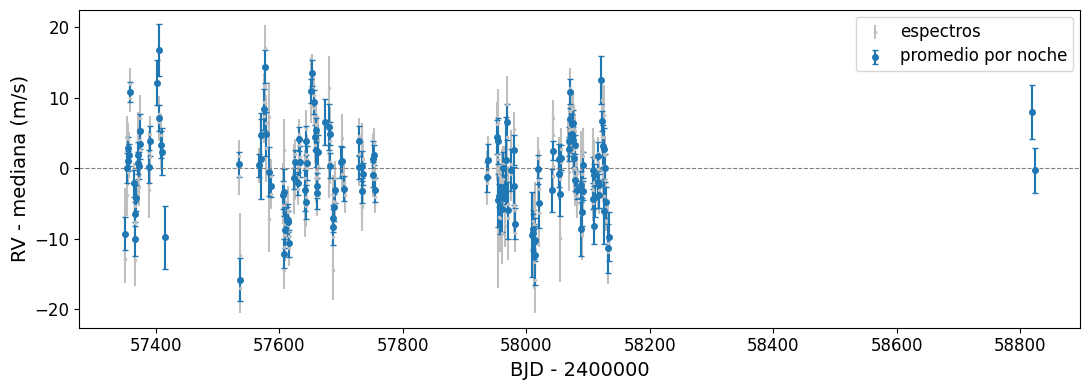

In [12]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
nights = promedio_por_noche(rv)
nights.to_csv(OUT / "RV_LHS1140_por_noche.csv", index=False)
print(len(rv), "espectros ->", len(nights), "noches |", (nights.n >= 2).sum(), "con 2 o mas espectros")
print("Por espectro: RMS =", round(rms_pond(rv.vrad.values, rv.svrad.values), 2), "m/s, error mediano =", round(rv.svrad.median(), 2), "m/s")
print("Por noche: RMS =", round(rms_pond(nights.vrad.values, nights.svrad.values), 2), "m/s, error mediano =", round(nights.svrad.median(), 2), "m/s")

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(rv.bjd - 2400000, rv.vrad - nights.vrad.median(), rv.svrad, fmt=".", color="0.75", ms=3, label="espectros")
ax.errorbar(nights.bjd - 2400000, nights.vrad - nights.vrad.median(), nights.svrad, fmt="o", ms=4, color="C0", capsize=2, label="promedio por noche")
ax.axhline(0, color="gray", ls="--", lw=0.8)
ax.set_xlabel("BJD - 2400000")
ax.set_ylabel("RV - mediana (m/s)")
ax.legend()
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "rv_por_noche.png", dpi=140)
plt.show()

## Periodograma GLS

Periodograma de los promedios por noche, con umbrales de falsa alarma por bootstrap y la funcion de ventana.

Picos mas altos:
   periodo_d  potencia
0     24.824     0.400
1     26.474     0.220
2     81.549     0.215
3     27.719     0.151
4     69.283     0.144
5    131.907     0.143
Umbrales de falsa alarma (bootstrap): {0.01: 0.173, 0.001: 0.187}
Potencia maxima cerca de P_c = 3.77794 d (+-3%): 0.086
Potencia maxima cerca de P_b = 24.73723 d (+-3%): 0.400


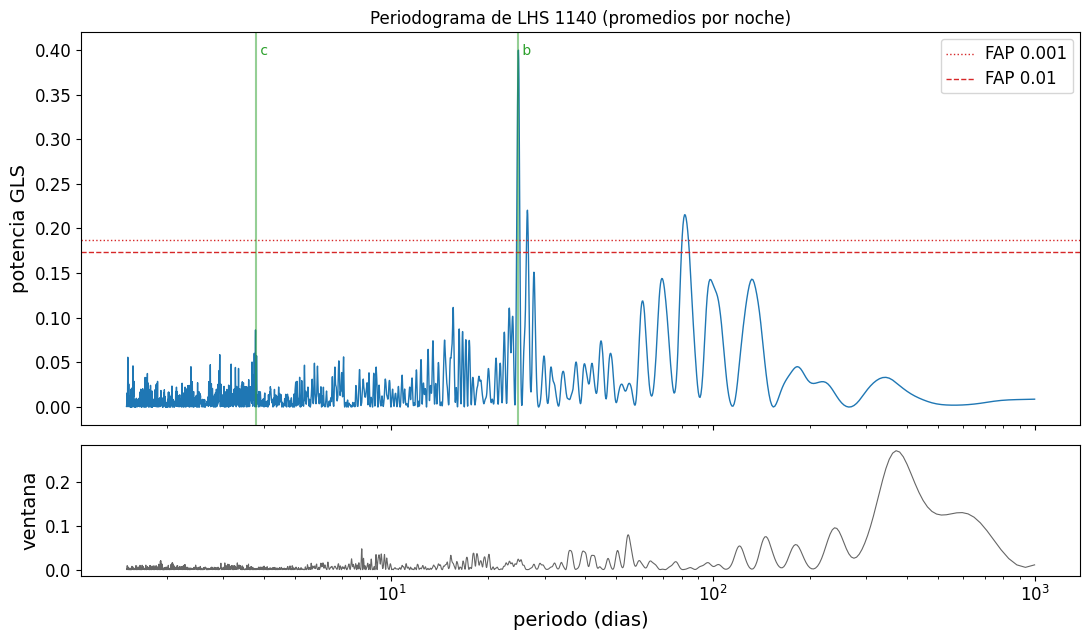

In [13]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
t, y, dy = nights.bjd.values, nights.vrad.values, nights.svrad.values
T = t.max() - t.min()
freq = np.arange(1 / P_MAX, 1 / P_MIN, 1 / (10 * T)) # sobremuestreo x10
p = gls(t, y, dy, freq)
umbral = fap_bootstrap(t, y, dy, freq, n=N_BOOT)
vent = ventana(t, freq)

print("Picos mas altos:")
print(picos(freq, p).round({"periodo_d": 3, "potencia": 3}))
print("Umbrales de falsa alarma (bootstrap):", {k: round(v, 3) for k, v in umbral.items()})
for nombre, P in P_PLANETAS.items():
    print(f"Potencia maxima cerca de P_{nombre} = {P} d (+-3%): {max_cerca(freq, p, P, 0.03):.3f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(1 / freq, p, color="C0", lw=1)
for a, ls in zip(sorted(umbral), (":", "--")):
    ax[0].axhline(umbral[a], color="C3", ls=ls, lw=1, label=f"FAP {a:g}")
for nombre, P in P_PLANETAS.items():
    ax[0].axvline(P, color="C2", ls="-", alpha=0.5, lw=1.5)
    ax[0].text(P, ax[0].get_ylim()[1] * 0.97, f" {nombre}", color="C2", va="top")
ax[0].set_ylabel("potencia GLS")
ax[0].legend()
ax[0].set_title("Periodograma de LHS 1140 (promedios por noche)")
ax[1].plot(1 / freq, vent, color="0.4", lw=0.8)
ax[1].set_ylabel("ventana")
ax[1].set_xscale("log")
ax[1].set_xlabel("periodo (dias)")
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "periodograma_gls.png", dpi=140)
plt.show()

## Ajuste de b y c

Se ajustan dos sinusoides con los periodos fijos de b y c (orbitas circulares) y se miran los residuos.

In [14]:
periodos = list(P_PLANETAS.values())
t0 = t.mean()
coef, res, K, eK, chi2r = ajuste_sinusoides(t, y, dy, periodos, t0)
print("chi2 reducido del ajuste:", round(chi2r, 2))
for (nombre, P), k, e in zip(P_PLANETAS.items(), K, eK):
    print(f"  {nombre}: P = {P} d (fijo)  K = {k:.2f} +- {e:.2f} m/s  ({k / e:.1f} sigma)")
print("RMS antes:", round(rms_pond(y, dy), 2), "m/s | despues de quitar b y c:", round(rms_pond(res, dy), 2), "m/s")
print("Nota: K es siempre positivo y se sesga hacia arriba cuando la señal es debil.")

chi2 reducido del ajuste: 3.62
  c: P = 3.77794 d (fijo)  K = 2.47 +- 0.47 m/s  (5.3 sigma)
  b: P = 24.73723 d (fijo)  K = 4.78 +- 0.45 m/s  (10.5 sigma)
RMS antes: 5.91 m/s | despues de quitar b y c: 4.33 m/s
Nota: K es siempre positivo y se sesga hacia arriba cuando la señal es debil.


### Residuos del ajuste
Periodograma de los residuos y sus picos mas altos.

In [15]:
p_res = gls(t, res, dy, freq)
print("Picos de los residuos:")
print(picos(freq, p_res, 4).round({"periodo_d": 3, "potencia": 3}))

Picos de los residuos:
   periodo_d  potencia
0    134.311     0.228
1     68.637     0.205
2     83.869     0.200
3     96.499     0.192


### Figura del ajuste
Cada planeta plegado a su periodo con el otro restado, y periodogramas de los datos y de los residuos.

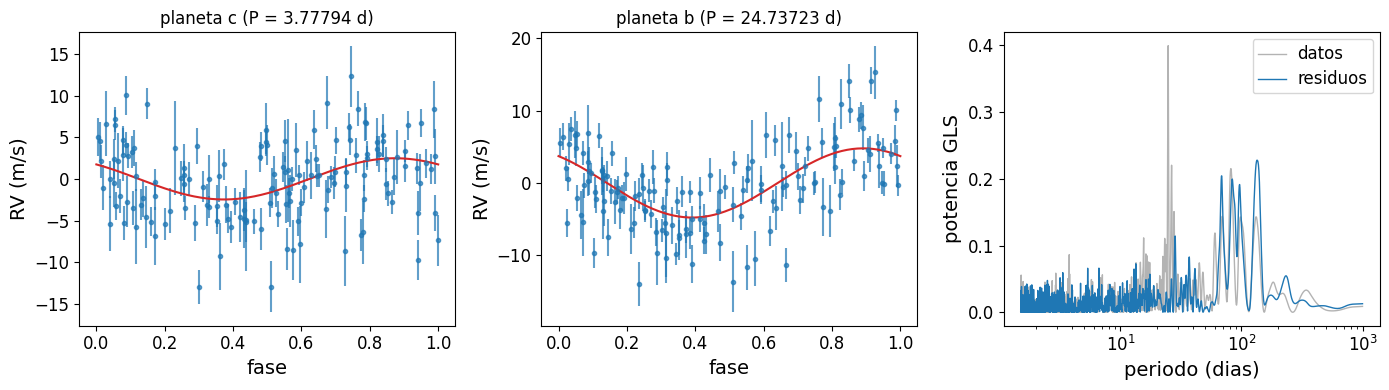

In [16]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for j, (nombre, P) in enumerate(P_PLANETAS.items()):
    otro = 1 - j
    tt = t - t0
    modelo_otro = coef[1 + 2 * otro] * np.sin(2 * np.pi * tt / periodos[otro]) + coef[2 + 2 * otro] * np.cos(2 * np.pi * tt / periodos[otro])
    yy = y - coef[0] - modelo_otro
    fase = ((tt / P) % 1)
    ax[j].errorbar(fase, yy, dy, fmt="o", ms=3, color="C0", alpha=0.7)
    ff = np.linspace(0, 1, 200)
    ax[j].plot(ff, coef[1 + 2 * j] * np.sin(2 * np.pi * ff) + coef[2 + 2 * j] * np.cos(2 * np.pi * ff), color="C3")
    ax[j].set_title(f"planeta {nombre} (P = {P} d)")
    ax[j].set_xlabel("fase")
    ax[j].set_ylabel("RV (m/s)")
ax[2].plot(1 / freq, p, color="0.7", lw=1, label="datos")
ax[2].plot(1 / freq, p_res, color="C0", lw=1, label="residuos")
ax[2].set_xscale("log")
ax[2].set_xlabel("periodo (dias)")
ax[2].set_ylabel("potencia GLS")
ax[2].legend()
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "ajuste_planetas.png", dpi=140)
plt.show()

## Sensibilidad al corte de S/N

Se repite el analisis con distintos cortes de S/N para ver si cambia el resultado.

In [17]:
# sensibilidad al corte de S/N (sin bootstrap, es rapido)
cortes = [0, 8, 10, 12]
filas, curvas = [], {}
for c in cortes:
    d = pd.read_csv(CSV).sort_values("bjd")
    d = d[d.snr47 >= c]
    nn = promedio_por_noche(d)
    if len(nn) < 20:
        continue
    tn, yn, dn = nn.bjd.values, nn.vrad.values, nn.svrad.values
    Tn = tn.max() - tn.min()
    fn = np.arange(1 / P_MAX, 1 / P_MIN, 1 / (10 * Tn))
    pn = gls(tn, yn, dn, fn)
    _, rn, Kn, eKn, chi2n = ajuste_sinusoides(tn, yn, dn, periodos, tn.mean())
    pk = picos(fn, pn, 1).iloc[0]
    curvas[c] = (fn, pn)
    filas.append(dict(corte_SN=("todos" if c == 0 else f">= {c}"), espectros=len(d), noches=len(nn),
                      RMS_ms=round(rms_pond(yn, dn), 2), error_mediano_ms=round(float(np.median(dn)), 2),
                      pico_d=round(float(pk.periodo_d), 2), pico_pot=round(float(pk.potencia), 3),
                      pot_c=round(max_cerca(fn, pn, P_PLANETAS["c"], 0.03), 3),
                      pot_b=round(max_cerca(fn, pn, P_PLANETAS["b"], 0.03), 3),
                      K_c=f"{Kn[0]:.2f}+-{eKn[0]:.2f}", K_b=f"{Kn[1]:.2f}+-{eKn[1]:.2f}"))

### Tabla de sensibilidad
Se guarda y se imprime la tabla con el RMS, el pico mas alto y los K de cada corte.

In [18]:
tabla = pd.DataFrame(filas)
tabla.to_csv(OUT / "sensibilidad_corte_SN.csv", index=False)
print(tabla)
print("la potencia GLS depende del numero de datos; compara la posicion de los picos y los K, no las alturas.")

  corte_SN  espectros  noches  RMS_ms  error_mediano_ms  pico_d  pico_pot  \
0    todos        293     147    5.91              2.04   24.82     0.400   
1     >= 8        258     132    5.90              1.96   24.82     0.405   
2    >= 10        207     112    5.25              1.90   24.78     0.374   
3    >= 12        141      83    5.43              1.83   24.79     0.405   

   pot_c  pot_b         K_c         K_b  
0  0.086  0.400  2.47+-0.47  4.78+-0.45  
1  0.090  0.405  2.43+-0.49  4.72+-0.47  
2  0.088  0.374  2.41+-0.53  4.39+-0.50  
3  0.119  0.405  2.94+-0.59  4.80+-0.57  
la potencia GLS depende del numero de datos; compara la posicion de los picos y los K, no las alturas.


### Periodogramas por corte
Periodogramas de cada corte con los periodos de b y c marcados en verde.

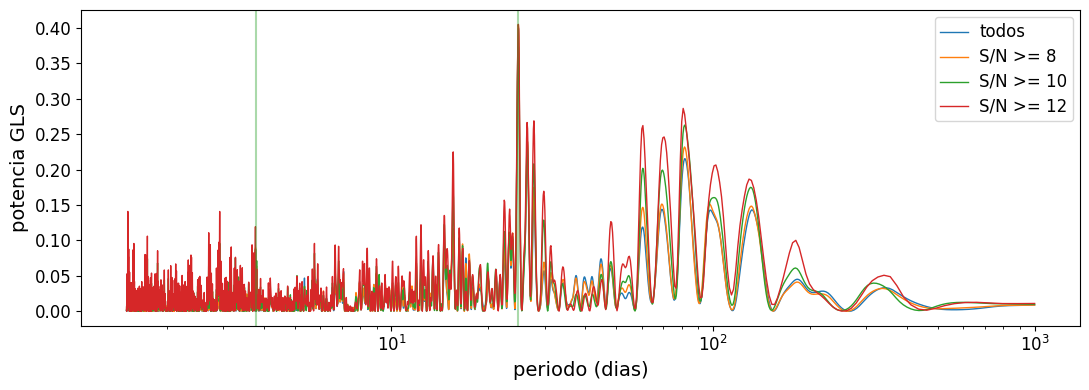

Guardado en /content/drive/MyDrive/LHS1140_HARPS/resultados_LBL/completa/analisis


In [19]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(figsize=(11, 4))
for c, (fn, pn) in curvas.items():
    ax.plot(1 / fn, pn, lw=1, label="todos" if c == 0 else f"S/N >= {c}")
for P in P_PLANETAS.values():
    ax.axvline(P, color="C2", alpha=0.4)
ax.set_xscale("log")
ax.set_xlabel("periodo (dias)")
ax.set_ylabel("potencia GLS")
ax.legend()
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "sensibilidad_periodogramas.png", dpi=140)
plt.show()
print("Guardado en", OUT)

## Indicadores de actividad y BERV

Se revisa si los picos de periodo largo de los residuos aparecen tambien en los indicadores de actividad y en la BERV.

In [20]:
# P_ROT (periodo de rotacion, d) viene del bloque de constantes; pon P_ROT = None para no dibujarlo

rdb_file = None
for p in sorted((DRIVE / "resultados_LBL" / "completa").glob("lbl_*.rdb")):
    if not p.name.startswith("lbl2"):
        rdb_file = p
        break
tab = pd.read_csv(rdb_file, sep="\t", skiprows=[1])
for c in tab.columns:
    if c != "DATE-OBS":
        tab[c] = pd.to_numeric(tab[c], errors="coerce")
tab["bjd"] = tab.rjd + 2400000.0
print("Tabla:", rdb_file.name, "|", len(tab), "filas")
print("Columnas:", tab.columns.tolist())

Tabla: lbl_LHS1140_tc_LHS1140_tc.rdb | 293 filas
Columnas: ['rjd', 'vrad', 'svrad', 'd2v', 'sd2v', 'd3v', 'sd3v', 'local_file_name', 'plot_date', 'dW', 'sdW', 'fwhm', 'sig_fwhm', 'contrast', 'sig_contrast', 'vrad_achromatic', 'svrad_achromatic', 'vrad_chromatic_slope', 'svrad_chromatic_slope', 'CRX', 'sCRX', 'FILENAME', 'HIERARCH ESO DRS BJD', 'HIERARCH ESO DET WIN1 DIT1', 'HIERARCH ESO TEL AIRM START', 'DATE-OBS', 'HIERARCH ESO DRS BERV', 'HIERARCH ESO DPR TYPE', 'TLPEH2O', 'TLPEOTR', 'ITE_RV', 'RESET_RV', 'SYSTVELO', 'HIERARCH ESO DRS CAL TH FILE', 'HIERARCH ESO OBS TARG NAME', 'HIERARCH ESO DRS SPE EXT SN47', 'CCF_EW', 'LBL_VERSION', 'LBL_VDATE', 'LBL_PDATE', 'LBL_SCI_DIR', 'vrad_g', 'svrad_g', 'vrad_g_0-2044', 'svrad_g_0-2044', 'vrad_g_2044-4088', 'svrad_g_2044-4088', 'vrad_407nm', 'svrad_407nm', 'vrad_423nm', 'svrad_423nm', 'vrad_439nm', 'svrad_439nm', 'vrad_455nm', 'svrad_455nm', 'vrad_473nm', 'svrad_473nm', 'vrad_491nm', 'svrad_491nm', 'vrad_509nm', 'svrad_509nm', 'vrad_529nm', 

### Indicadores de actividad
Se escogen las columnas de indicadores de actividad de la tabla de LBL (CRX, DLW, d2v, dW, fwhm...) y se cruzan con las noches

In [21]:
indicadores = [c for c in tab.columns if re.fullmatch(r"(?i)(CRX|DLW|D2V|D3V|DTEMP|DDV|per_epoch_DDV|dW|fwhm|contrast|TLPEH2O|TLPEOTR)", c)]
print("Indicadores usados:", indicadores if indicadores else "NINGUNO (mira la lista de columnas y ajusta la expresion de arriba)")

m = pd.merge_asof(rv.sort_values("bjd")[["bjd", "berv"]], tab[["bjd"] + indicadores].sort_values("bjd"),
                  on="bjd", tolerance=1e-3, direction="nearest")
m["noche"] = np.floor(m.bjd).astype(int)
act = m.groupby("noche")[["berv"] + indicadores].mean().loc[nights.noche.values]

Indicadores usados: ['d2v', 'd3v', 'dW', 'fwhm', 'contrast', 'CRX', 'TLPEH2O', 'TLPEOTR']


### Periodogramas de los indicadores
GLS de los residuos y de cada indicador. Lineas rojas: picos de los residuos. Linea verde: rotacion estelar

In [22]:
p_res = gls(t, res, dy, freq)
top_res = picos(freq, p_res, 4)
series = {"RV residuos (b y c restados)": res}
series.update({c: act[c].values for c in ["berv"] + indicadores})

filas = []

### Periodogramas y tabla de cada indicador
Para cada serie se calcula el GLS y se dibuja. Tambien se anota su correlacion con los residuos y su potencia en los picos de los residuos.

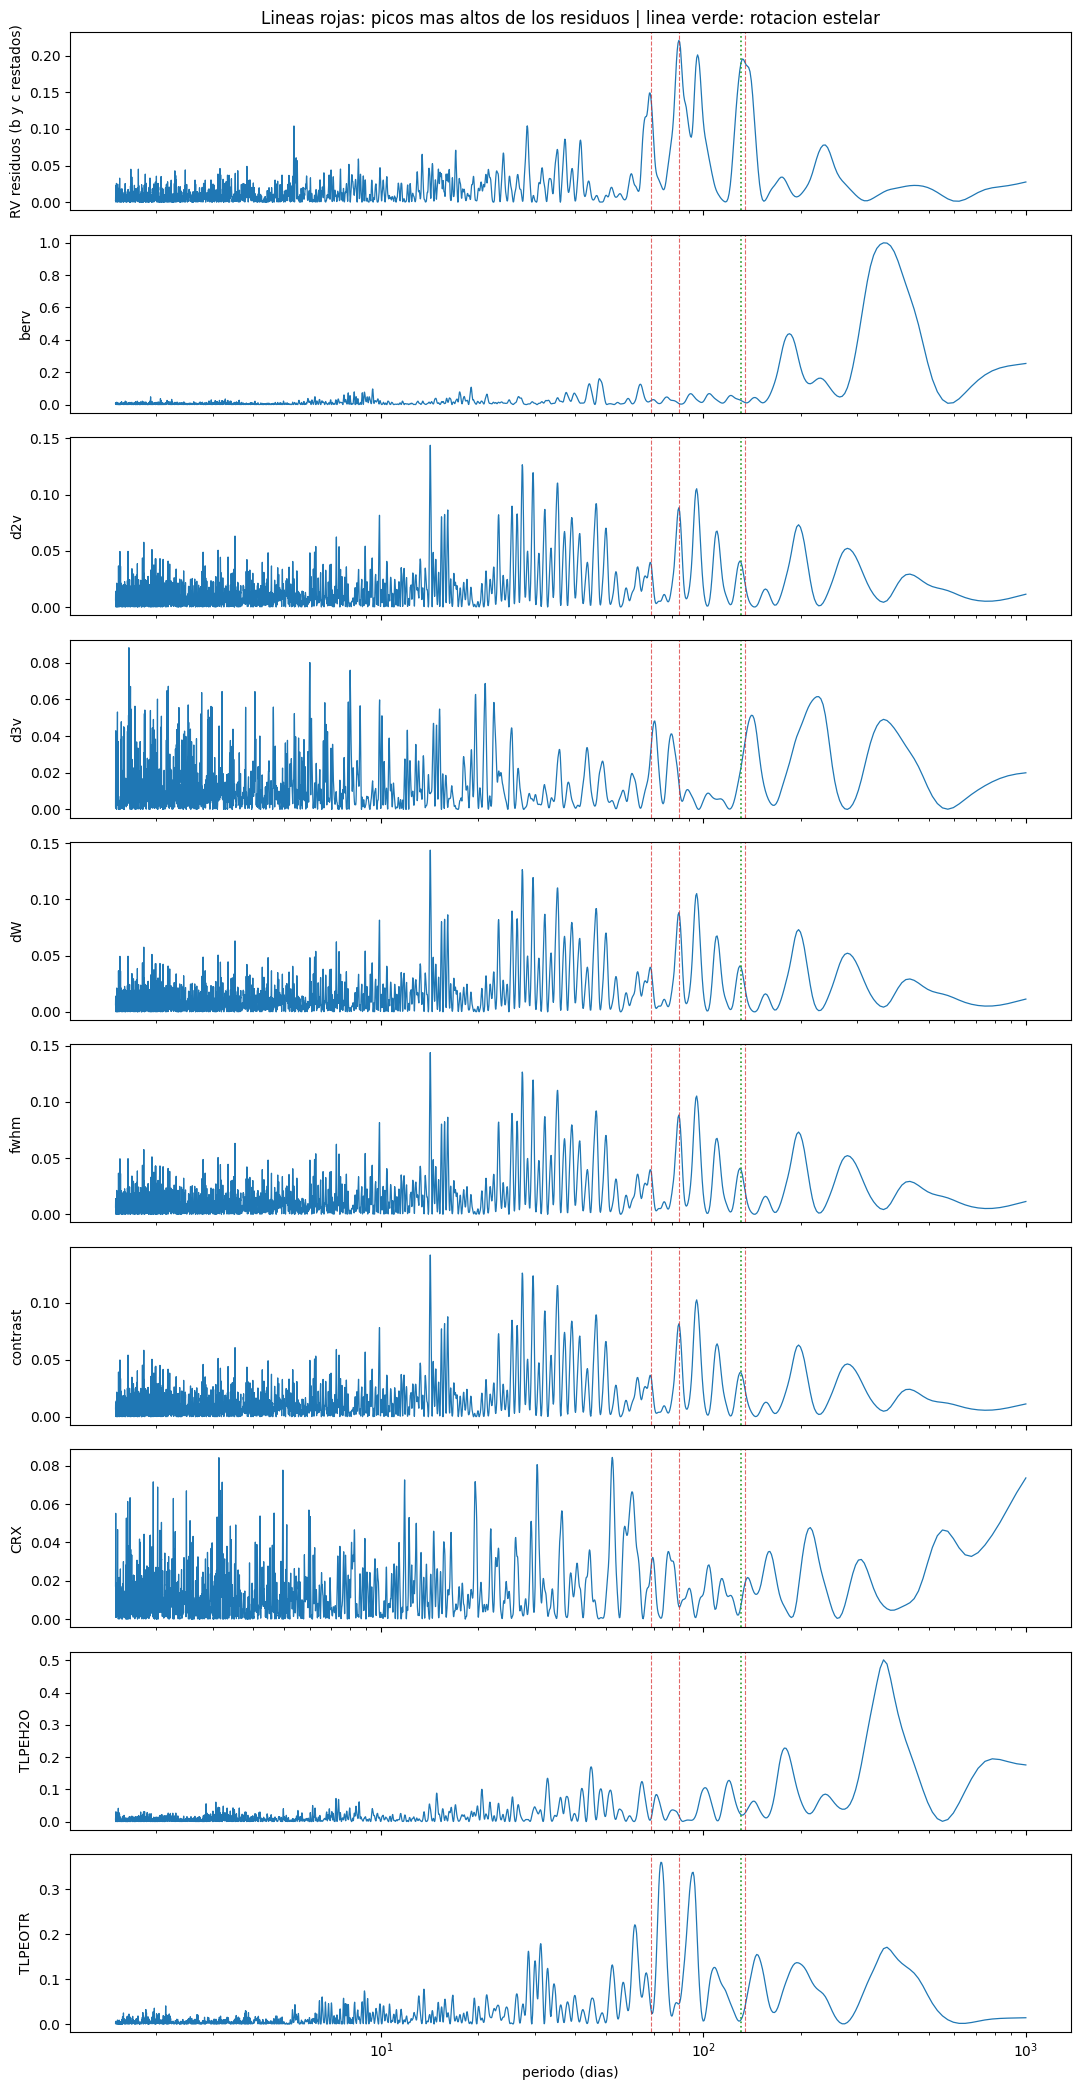

In [23]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(len(series), 1, figsize=(11, 2.1 * len(series)), sharex=True)
ax = np.atleast_1d(ax)
for a, (nombre, v) in zip(ax, series.items()):
    ok = np.isfinite(v)
    pv = gls(t[ok], v[ok], np.ones(ok.sum()), freq) # pesos iguales: es un diagnostico
    if not np.any(np.isfinite(pv)): # serie constante o sin datos: el GLS da NaN
        print(f"{nombre}: {ok.sum()} noches con dato, desviacion = {np.nanstd(v):.3g}; se omite")
        a.set_ylabel(nombre + " (omitida)", fontsize=8)
        continue
    a.plot(1 / freq, pv, lw=0.9)
    a.set_ylabel(nombre, fontsize=8)
    for P in top_res.periodo_d.iloc[:3]:
        a.axvline(P, color="C3", ls="--", lw=0.8, alpha=0.7)
    if P_ROT:
        a.axvline(P_ROT, color="C2", ls=":", lw=1.2)
    r = np.corrcoef(res[ok], v[ok])[0, 1] if nombre != "RV residuos (b y c restados)" else np.nan
    fila = dict(serie=nombre, correlacion_con_residuos=round(r, 2) if np.isfinite(r) else "",
                pico_principal_d=round(float(picos(freq, pv, 1).periodo_d.iloc[0]), 1))
    for P in top_res.periodo_d.iloc[:3]:
        fila[f"pot_a_{P:.0f}d"] = round(float(max_cerca(freq, pv, P, 0.05)), 3)
    filas.append(fila)
ax[-1].set_xscale("log")
ax[-1].set_xlabel("periodo (dias)")
ax[0].set_title("Lineas rojas: picos mas altos de los residuos | linea verde: rotacion estelar")
letra_grande(fig, 10, 10, 10)
plt.tight_layout()
plt.savefig(OUT / "actividad_vs_residuos.png", dpi=140)
plt.show()

### Tabla de indicadores
Correlacion de cada indicador con los residuos y su potencia en los periodos de los picos

In [24]:
tabla_act = pd.DataFrame(filas)
print(tabla_act)
print("Correlacion significativa (95 %) si |r| > ~" + str(round(2 / np.sqrt(len(t)), 2)) + ". Un pico de los residuos que tambien esta en CRX/DLW/BERV apunta a actividad o sistematico, no a un planeta.")

                          serie correlacion_con_residuos  pico_principal_d  \
0  RV residuos (b y c restados)                                       83.9   
1                          berv                     -0.1             361.8   
2                           d2v                    -0.43              14.2   
3                           d3v                     0.03               1.7   
4                            dW                    -0.43              14.2   
5                          fwhm                    -0.43              14.2   
6                      contrast                     0.44              14.2   
7                           CRX                     -0.1              52.1   
8                       TLPEH2O                    -0.04             361.8   
9                       TLPEOTR                     0.15              73.8   

   pot_a_134d  pot_a_69d  pot_a_84d  
0       0.196      0.149      0.221  
1       0.032      0.060      0.026  
2       0.041      0.040   

### Diagnostico: ¿d2v, dW y fwhm son realmente distintos?

En la descorrelacion salieron resultados identicos para los tres. La correlacion ya es 1.0 en la tabla original de LBL (**tab**) y sigue siendo 1.0 despues del cruce y el promedio por noche (**act**). Entonces vienen asi desde LBL y el cruce esta bien: d2v, dW y fwhm cuentan como un solo indicador. (CCF_EW es constante y se omite.)

In [25]:
ok = np.isfinite(tab["d2v"]) & np.isfinite(tab["dW"]) & np.isfinite(tab["fwhm"])
print("tabla LBL  d2v-dW  :", round(np.corrcoef(tab["d2v"][ok], tab["dW"][ok])[0, 1], 3))
print("tabla LBL  d2v-fwhm:", round(np.corrcoef(tab["d2v"][ok], tab["fwhm"][ok])[0, 1], 3))

# despues del cruce y del promedio por noche (lo que usa la descorrelacion)
ok2 = np.isfinite(act["d2v"]) & np.isfinite(act["dW"]) & np.isfinite(act["fwhm"])
print("por noche  d2v-dW  :", round(np.corrcoef(act["d2v"][ok2], act["dW"][ok2])[0, 1], 3))
print("por noche  d2v-fwhm:", round(np.corrcoef(act["d2v"][ok2], act["fwhm"][ok2])[0, 1], 3))
print("La tabla de LBL ya trae d2v, dW y fwhm con correlacion 1: vienen asi desde LBL, no es un error del cruce.")

tabla LBL  d2v-dW  : 1.0
tabla LBL  d2v-fwhm: 1.0
por noche  d2v-dW  : 1.0
por noche  d2v-fwhm: 1.0
La tabla de LBL ya trae d2v, dW y fwhm con correlacion 1: vienen asi desde LBL, no es un error del cruce.


## Residuos

Umbral de falsa alarma de los residuos y prueba de un tercer periodo.

In [26]:
P3_MANUAL = None # pon aqui un periodo (dias) para probarlo a mano; None = el pico mas alto de los residuos

umbral_res = fap_bootstrap(t, res, dy, freq, n=N_BOOT)
top = picos(freq, p_res, 5)
top["> FAP 0.01"] = top.potencia > umbral_res[0.01]
top["> FAP 0.001"] = top.potencia > umbral_res[0.001]
print("Umbrales de falsa alarma de los residuos:", {k: round(v, 3) for k, v in umbral_res.items()})
print(top.round({"periodo_d": 2, "potencia": 3}))
print("Aviso: el bootstrap supone ruido blanco; con ruido correlacionado (actividad) subestima la falsa alarma.")

Umbrales de falsa alarma de los residuos: {0.01: 0.154, 0.001: 0.17}
   periodo_d  potencia  > FAP 0.01  > FAP 0.001
0     134.31     0.228        True         True
1      68.64     0.205        True         True
2      83.87     0.200        True         True
3      96.50     0.192        True         True
4      28.30     0.114       False        False
Aviso: el bootstrap supone ruido blanco; con ruido correlacionado (actividad) subestima la falsa alarma.


### Tercer periodo
Se ajusta una tercera sinusoide al pico mas alto de los residuos (o al periodo puesto a mano) y se compara con el ajuste de b y c usando el BIC

In [27]:
P3 = P3_MANUAL or float(top.periodo_d.iloc[0])
per3 = periodos + [P3]
c2, r2, K2, eK2, chi2r2 = ajuste_sinusoides(t, y, dy, periodos, t0)
c3, r3, K3, eK3, chi2r3 = ajuste_sinusoides(t, y, dy, per3, t0)
chi2_2, chi2_3 = np.sum((r2 / dy)**2), np.sum((r3 / dy)**2)
dBIC = (chi2_2 - chi2_3) / chi2r2 - 2 * np.log(len(t)) # >0 favorece 3 señales; chi2 escalado por el chi2 reducido de 2 planetas
print(f"Tercer periodo candidato: {P3:.2f} d | K = {K3[2]:.2f} +- {eK3[2]:.2f} m/s | RMS {rms_pond(r2, dy):.2f} -> {rms_pond(r3, dy):.2f} m/s")
print(f"Delta BIC (3 señales vs 2) = {dBIC:.1f}  (>10 seria fuerte; pero el periodo se eligio mirando los datos, asi que sobrestima)")

Tercer periodo candidato: 134.31 d | K = 2.60 +- 0.40 m/s | RMS 4.33 -> 3.90 m/s
Delta BIC (3 señales vs 2) = 22.5  (>10 seria fuerte; pero el periodo se eligio mirando los datos, asi que sobrestima)


### Ajuste de tres señales
Se compara el K de b y c del ajuste de dos señales con el del ajuste que incluye el periodo del pico más alto de los residuos, para ver si esa señal infla el K de los planetas.

In [28]:
# K2 es del ajuste de dos señales y K3 del de tres (c va primero en periodos); la tercera es la de P3
for j, nombre in enumerate(P_PLANETAS):
    print(f"{nombre}: dos señales K = {K2[j]:.2f} +- {eK2[j]:.2f} m/s | tres señales K = {K3[j]:.2f} +- {eK3[j]:.2f} m/s | cambio = {K3[j] - K2[j]:+.2f} m/s")
print(f"Tercera señal ({P3:.1f} d): K = {K3[2]:.2f} +- {eK3[2]:.2f} m/s")

c: dos señales K = 2.47 +- 0.47 m/s | tres señales K = 2.39 +- 0.41 m/s | cambio = -0.08 m/s
b: dos señales K = 4.78 +- 0.45 m/s | tres señales K = 4.71 +- 0.40 m/s | cambio = -0.07 m/s
Tercera señal (134.3 d): K = 2.60 +- 0.40 m/s


### Coherencia entre mitades
Se ajusta el candidato por separado en la primera y en la segunda mitad de los datos. Una señal real mantiene su fase

In [29]:
# coherencia entre temporadas: misma fase en la primera y la segunda mitad de los datos
def fase_K(tt, yy, dd, pers, j):
    c, _, K, eK, _ = ajuste_sinusoides(tt, yy, dd, pers, t0)
    return K[j], eK[j], np.degrees(np.arctan2(c[2 + 2 * j], c[1 + 2 * j])) % 360

mitad = t < np.median(t)
print("Coherencia (K y fase en grados; una señal real mantiene la fase):")
for etiqueta, mk in (("todos", np.ones_like(mitad)), ("1a mitad", mitad), ("2a mitad", ~mitad)):
    kb, ekb, fb = fase_K(t[mk], y[mk], dy[mk], per3, 1)
    k3, ek3, f3 = fase_K(t[mk], y[mk], dy[mk], per3, 2)
    print(etiqueta, "(N =", mk.sum(), ") | b: K =", round(kb, 1), "+-", round(ekb, 1), "fase =", int(round(fb)), "| periodo", round(P3), "d: K =", round(k3, 1), "+-", round(ek3, 1), "fase =", int(round(f3)))
print("Control: la fase de b debe repetirse entre mitades. Si la del candidato cambia mucho, apunta a ruido/actividad.")

Coherencia (K y fase en grados; una señal real mantiene la fase):
todos (N = 147 ) | b: K = 4.7 +- 0.4 fase = 131 | periodo 134 d: K = 2.6 +- 0.4 fase = 98
1a mitad (N = 73 ) | b: K = 5.7 +- 0.6 fase = 141 | periodo 134 d: K = 4.0 +- 0.7 fase = 97
2a mitad (N = 74 ) | b: K = 4.6 +- 0.5 fase = 122 | periodo 134 d: K = 1.8 +- 0.4 fase = 78
Control: la fase de b debe repetirse entre mitades. Si la del candidato cambia mucho, apunta a ruido/actividad.


### Residuos plegados
Periodograma de los residuos con los umbrales de falsa alarma, y residuos plegados al tercer periodo

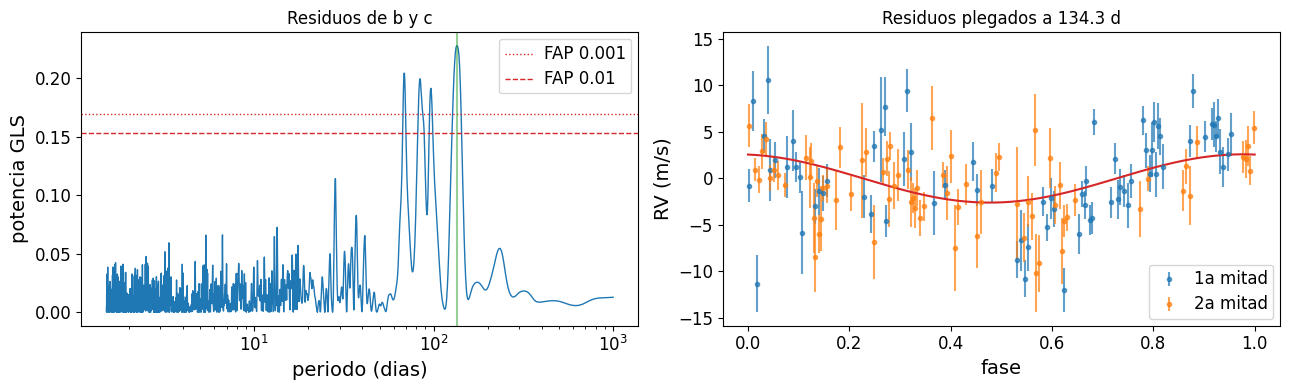

In [30]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(1 / freq, p_res, lw=1, color="C0")
for a_, ls in zip(sorted(umbral_res), (":", "--")):
    ax[0].axhline(umbral_res[a_], color="C3", ls=ls, lw=1, label=f"FAP {a_:g}")
ax[0].axvline(P3, color="C2", alpha=0.5)
ax[0].legend()
ax[0].set_xscale("log")
ax[0].set_xlabel("periodo (dias)")
ax[0].set_ylabel("potencia GLS")
ax[0].set_title("Residuos de b y c")
fase = ((t - t0) / P3) % 1
ax[1].errorbar(fase[mitad], r2[mitad], dy[mitad], fmt="o", ms=3, color="C0", alpha=0.7, label="1a mitad")
ax[1].errorbar(fase[~mitad], r2[~mitad], dy[~mitad], fmt="o", ms=3, color="C1", alpha=0.7, label="2a mitad")
ff = np.linspace(0, 1, 200)
ax[1].plot(ff, c3[5] * np.sin(2 * np.pi * ff) + c3[6] * np.cos(2 * np.pi * ff), color="C3")
ax[1].set_title(f"Residuos plegados a {P3:.1f} d")
ax[1].set_xlabel("fase")
ax[1].set_ylabel("RV (m/s)")
ax[1].legend()
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "residuos_tercer_periodo.png", dpi=140)
plt.show()

## Descorrelacion con indicadores

Se quita de los residuos la parte ligada a d2v, dW y fwhm y se mira que picos sobreviven. Como los tres indicadores son identicos (ver el diagnostico de la seccion Indicadores de actividad y BERV), los conjuntos con varios indicadores dan lo mismo que uno solo.

In [31]:
conjuntos = {"d2v": ["d2v"], "dW": ["dW"], "fwhm": ["fwhm"], "d2v + dW": ["d2v", "dW"], "d2v + dW + fwhm": ["d2v", "dW", "fwhm"]}
conjuntos = {k: v for k, v in conjuntos.items() if all(c in act.columns for c in v)}
N_BOOT_DESC = min(N_BOOT, 200)
periodos_top = top.periodo_d.iloc[:4].values # los 4 picos mas altos de los residuos (de la seccion Residuos)

### Funcion de descorrelacion
Regresion ponderada de los residuos contra los indicadores estandarizados. Devuelve los residuos limpios

In [32]:
def descorrelacionar(res, dy, X):
    # regresion ponderada res ~ a + X; devuelve los residuos limpios y el ajuste
    A = np.column_stack([np.ones(len(res))] + [(x - np.nanmean(x)) / np.nanstd(x) for x in X.T])
    coef, *_ = np.linalg.lstsq(A / dy[:, None], res / dy, rcond=None)
    return res - A @ coef, coef

### Descorrelacion por conjunto
Para cada conjunto de indicadores se quita su efecto de los residuos, se recalcula el GLS y su umbral de falsa alarma, y se anota la potencia en los picos

In [33]:
filas, curvas = [], {"residuos de b y c": p_res}
fila0 = dict(conjunto="(sin descorrelar)", RMS_ms=round(rms_pond(res, dy), 2))
for P in periodos_top:
    fila0[f"pot_{P:.0f}d"] = round(float(max_cerca(freq, p_res, P, 0.05)), 3)
fila0["FAP_0.01"] = round(float(umbral_res[0.01]), 3)
filas.append(fila0)

for nombre, cols in conjuntos.items():
    X = act[cols].values
    ok = np.all(np.isfinite(X), axis=1)
    tc, rc, dc = t[ok], res[ok], dy[ok]
    limpio, coef = descorrelacionar(rc, dc, X[ok])
    pc = gls(tc, limpio, dc, freq)
    um = fap_bootstrap(tc, limpio, dc, freq, n=N_BOOT_DESC)
    curvas[f"sin {nombre}"] = pc
    f = dict(conjunto=nombre, RMS_ms=round(rms_pond(limpio, dc), 2))
    for P in periodos_top:
        f[f"pot_{P:.0f}d"] = round(float(max_cerca(freq, pc, P, 0.05)), 3)
    f["FAP_0.01"] = round(um[0.01], 3)
    filas.append(f)
    print(f"{nombre}: coeficientes estandarizados (m/s por desviacion tipica) =", np.round(coef[1:], 2))

d2v: coeficientes estandarizados (m/s por desviacion tipica) = [-1.91]
dW: coeficientes estandarizados (m/s por desviacion tipica) = [-1.91]
fwhm: coeficientes estandarizados (m/s por desviacion tipica) = [-1.91]
d2v + dW: coeficientes estandarizados (m/s por desviacion tipica) = [-0.96 -0.96]
d2v + dW + fwhm: coeficientes estandarizados (m/s por desviacion tipica) = [-0.64 -0.64 -0.64]


### Tabla y grafica
Tabla de resultados y periodogramas de los residuos antes y despues de descorrelar

            conjunto  RMS_ms  pot_134d  pot_69d  pot_84d  pot_96d  FAP_0.01
0  (sin descorrelar)    4.33     0.228    0.205    0.200    0.192     0.154
1                d2v    3.92     0.232    0.160    0.166    0.124     0.155
2                 dW    3.92     0.232    0.160    0.166    0.124     0.155
3               fwhm    3.92     0.232    0.160    0.166    0.124     0.155
4           d2v + dW    3.92     0.232    0.160    0.166    0.124     0.155
5    d2v + dW + fwhm    3.92     0.232    0.160    0.166    0.124     0.155
Si los picos caen por debajo de FAP_0.01 al quitar d2v/dW/fwhm, la variacion esta ligada a la forma de las lineas (actividad o instrumento).
esto tambien borra cualquier señal planetaria que se parezca al indicador; no es una prueba definitiva.


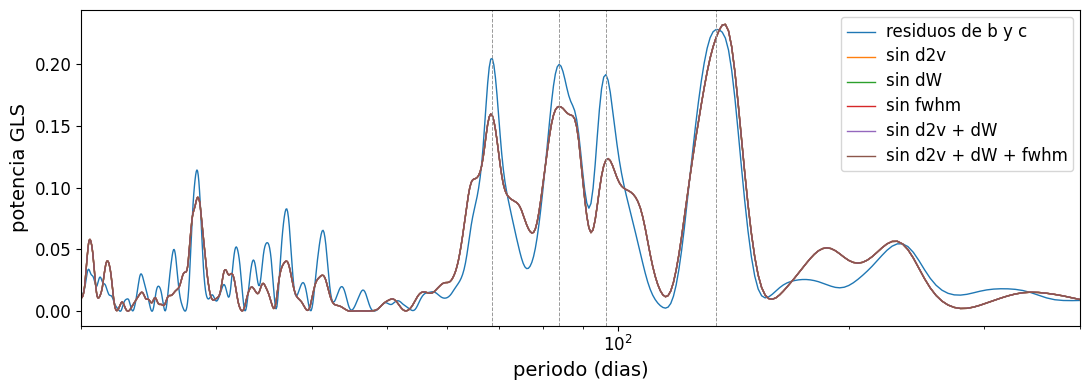

In [34]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
tabla9 = pd.DataFrame(filas)
tabla9.to_csv(OUT / "descorrelacion_indicadores.csv", index=False)
print(tabla9)
print("Si los picos caen por debajo de FAP_0.01 al quitar d2v/dW/fwhm, la variacion esta ligada a la forma de las lineas (actividad o instrumento).")
print("esto tambien borra cualquier señal planetaria que se parezca al indicador; no es una prueba definitiva.")

fig, ax = plt.subplots(figsize=(11, 4))
for etiqueta, pv in curvas.items():
    ax.plot(1 / freq, pv, lw=1, label=etiqueta)
for P in periodos_top:
    ax.axvline(P, color="0.6", ls="--", lw=0.7)
ax.set_xlim(20, 400)
ax.set_xscale("log")
ax.set_xlabel("periodo (dias)")
ax.set_ylabel("potencia GLS")
ax.legend()
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "descorrelacion_indicadores.png", dpi=140)
plt.show()

## Comparacion con la literatura

Se comparan los K de b y c con los de la literatura (Cadieux et al. 2024, Tabla 1 y Tabla D2).

In [35]:
# D17, M19 y LB20: tabla 1 de cadieux et al. (2024); C24: tabla 1 y tabla d2
LIT_K = {
    "b": {"D17 (HARPS)": (5.34, 1.10), "M19 (HARPS)": (4.85, 0.55), "LB20 (ESPRESSO, CCF)": (4.21, 0.24), "C24 (ESPRESSO, LBL)": (3.80, 0.11)},
    "c": {"M19 (HARPS)": (2.35, 0.49), "LB20 (ESPRESSO, CCF)": (2.22, 0.20), "C24 (ESPRESSO, LBL)": (2.42, 0.07)},
}
LIT_ROT = {"C24 (Tabla C1)": (131, 5), "C24 (GP cuasi-periodico sobre RV, Tabla D2)": (133, 3)}
LIT_GP_AMP = (2.8, 0.8) # m/s, amplitud del GP de actividad en C24, tabla d2 (+1.0/-0.6, aqui simetrizada)

nombres = list(P_PLANETAS.keys())
filas = []
for j, nombre in enumerate(nombres):
    if nombre not in LIT_K:
        continue
    for ref, (k_lit, e_lit) in LIT_K[nombre].items():
        dif = (K2[j] - k_lit) / np.hypot(eK2[j], e_lit)
        filas.append(dict(planeta=nombre, referencia=ref, K_literatura=f"{k_lit:.2f}+-{e_lit:.2f}",
                          K_este_trabajo=f"{K2[j]:.2f}+-{eK2[j]:.2f}", diferencia_sigma=round(float(dif), 1)))
tabla10 = pd.DataFrame(filas)
tabla10.to_csv(OUT / "comparacion_literatura_K.csv", index=False)
print(tabla10)

print()
print(f"Periodo del exceso en estos datos: {P3:.1f} d  |  K del exceso: {K3[2]:.2f}+-{eK3[2]:.2f} m/s")
for ref, (p_lit, e_lit) in LIT_ROT.items():
    print(f"  rotacion {ref}: {p_lit}+-{e_lit} d  -> diferencia {(P3 - p_lit) / e_lit:+.1f} sigma (solo error de la literatura)")
print(f"  amplitud del GP de actividad en C24: {LIT_GP_AMP[0]}+-{LIT_GP_AMP[1]} m/s  (la de estos datos, como sinusoide: {K3[2]:.1f} m/s)")
print("la diferencia en sigma de arriba ignora la incertidumbre del periodo medido (aprox. P^2/T, varios dias con esta cobertura).")
print("Notas: C24 uso solo ESPRESSO (seccion 2.4 del articulo: RMS 4.07 m/s, error mediano 0.36 m/s); los datos HARPS tienen RMS", round(rms_pond(y, dy), 2), "y error mediano", round(np.median(dy), 2), "m/s.")

  planeta            referencia K_literatura K_este_trabajo  diferencia_sigma
0       c           M19 (HARPS)   2.35+-0.49     2.47+-0.47               0.2
1       c  LB20 (ESPRESSO, CCF)   2.22+-0.20     2.47+-0.47               0.5
2       c   C24 (ESPRESSO, LBL)   2.42+-0.07     2.47+-0.47               0.1
3       b           D17 (HARPS)   5.34+-1.10     4.78+-0.45              -0.5
4       b           M19 (HARPS)   4.85+-0.55     4.78+-0.45              -0.1
5       b  LB20 (ESPRESSO, CCF)   4.21+-0.24     4.78+-0.45               1.1
6       b   C24 (ESPRESSO, LBL)   3.80+-0.11     4.78+-0.45               2.1

Periodo del exceso en estos datos: 134.3 d  |  K del exceso: 2.60+-0.40 m/s
  rotacion C24 (Tabla C1): 131+-5 d  -> diferencia +0.7 sigma (solo error de la literatura)
  rotacion C24 (GP cuasi-periodico sobre RV, Tabla D2): 133+-3 d  -> diferencia +0.4 sigma (solo error de la literatura)
  amplitud del GP de actividad en C24: 2.8+-0.8 m/s  (la de estos datos, como sinusoid

## Prueba de cromaticidad

K por banda de longitud de onda (Cadieux et al. 2024, Apendice D.3). Una señal planetaria debe tener el mismo K en todas las bandas.

In [36]:
# una señal Doppler real debe tener el mismo K en todas las bandas (dK/dlambda ~ 0) y el promedio de los K_lambda
# debe coincidir con el K del espectro completo. Una señal de actividad suele ser cromatica.
P_EXTRA = [P3] # periodos extra a probar, ademas de b y c (p. ej. [P3, 84.0])
LAMBDA_MANUAL = {} # si los nombres de banda no traen la longitud de onda: {'blue': 430, 'green': 530, 'red': 630} (nm)

### Bandas de longitud de onda
Se buscan en la tabla de LBL las columnas de velocidad por banda (vrad_banda) y se dejan las bandas con longitud de onda

In [37]:
# bandas disponibles en la tabla de LBL: columnas vrad_<banda> con su svrad_<banda>
bandas = {}
for c in tab.columns:
    mm = re.fullmatch(r"vrad_(.+)", c)
    if mm and "slope" not in mm.group(1).lower() and f"s{c}" in tab.columns:
        bandas[mm.group(1)] = (c, f"s{c}")
# solo bandas con longitud de onda (407nm ... 687nm): quita achromatic, g, g_0-2044, g_2044-4088
bandas = {k: v for k, v in bandas.items() if re.fullmatch(r"\d+nm", k)}
print("Bandas encontradas:", list(bandas) if bandas else "NINGUNA -> mira la lista de columnas de la tabla de LBL y ajusta la expresion")

Bandas encontradas: ['407nm', '423nm', '439nm', '455nm', '473nm', '491nm', '509nm', '529nm', '549nm', '570nm', '591nm', '614nm', '637nm', '662nm', '687nm']


### Longitud de onda de cada banda
Funcion que saca la longitud de onda del nombre de la banda, y cruce de las velocidades por banda con las noches

In [38]:
def lambda_de(nombre, i):
    if nombre in LAMBDA_MANUAL:
        return float(LAMBDA_MANUAL[nombre]), True
    mm = re.search(r"(\d+(?:\.\d+)?)", nombre)
    if mm and 300 <= float(mm.group(1)) <= 2500:
        return float(mm.group(1)), True
    return float(i), False # sin longitud de onda: se usa el orden de la banda

cols_b = [c for par in bandas.values() for c in par]
mb = pd.merge_asof(rv.sort_values("bjd")[["bjd"]], tab[["bjd"] + cols_b].sort_values("bjd"),
                   on="bjd", tolerance=1e-3, direction="nearest")
mb["noche"] = np.floor(mb.bjd).astype(int)

### K en cada banda
Se ajusta el K de cada señal en cada banda y se compara con el K del espectro completo

In [39]:
per_b = periodos + P_EXTRA
etiquetas = list(P_PLANETAS.keys()) + [f"{P:.0f} d" for P in P_EXTRA]
K_full, eK_full = ajuste_sinusoides(t, y, dy, per_b, t0)[2:4]

filas, lam, Kb_, eKb_ = [], [], [], []
for i, (nombre, (cv, cs)) in enumerate(bandas.items()):
    g = mb[["noche", cv, cs]].dropna()
    g = g[g[cs] > 0]
    filas_n = []
    for noche, d in g.groupby("noche"):
        w = 1 / d[cs]**2
        filas_n.append((noche, np.sum(w * d[cv]) / np.sum(w), 1 / np.sqrt(np.sum(w))))
    bn = pd.DataFrame(filas_n, columns=["noche", "v", "e"]).merge(nights[["noche", "bjd"]], on="noche")
    if len(bn) < 30:
        print(f"Banda {nombre}: solo {len(bn)} noches, se omite")
        continue
    _, _, Kk, eKk, _ = ajuste_sinusoides(bn.bjd.values, bn.v.values, bn.e.values, per_b, t0)
    lb, ok_l = lambda_de(nombre, i)
    lam.append(lb)
    Kb_.append(Kk)
    eKb_.append(eKk)
    for j, et in enumerate(etiquetas):
        filas.append(dict(banda=nombre, lambda_nm=lb if ok_l else np.nan, senal=et, K=round(float(Kk[j]), 2), eK=round(float(eKk[j]), 2)))
lam, Kb_, eKb_ = np.array(lam), np.array(Kb_), np.array(eKb_)
pd.DataFrame(filas).to_csv(OUT / "cromaticidad_K_por_banda.csv", index=False)
usa_nm = all(lambda_de(n, i)[1] for i, n in enumerate(bandas))
unidad = "por 100 nm" if usa_nm else "por banda (sin longitud de onda: define LAMBDA_MANUAL)"

Banda 407nm: solo 0 noches, se omite
Banda 423nm: solo 0 noches, se omite
Banda 439nm: solo 0 noches, se omite


### Pendiente de K con la longitud de onda
Se ajusta una recta de K contra longitud de onda. Una señal planetaria debe tener pendiente cercana a 0

In [40]:
res_c = []
for j, et in enumerate(etiquetas):
    Kj, ej = Kb_[:, j], np.maximum(eKb_[:, j], 1e-6)
    w = 1 / ej**2
    Kmed, eKmed = np.sum(w * Kj) / np.sum(w), 1 / np.sqrt(np.sum(w))
    x = (lam - lam.mean()) / (100.0 if usa_nm else 1.0)
    A = np.column_stack([np.ones_like(x), x])
    cov = np.linalg.inv(A.T @ (A / ej[:, None]**2))
    coef = cov @ (A.T @ (Kj / ej**2))
    chi2r = np.sum(((Kj - A @ coef) / ej)**2) / max(1, len(Kj) - 2)
    pend, epend = coef[1], np.sqrt(cov[1, 1] * max(1.0, chi2r))
    res_c.append(dict(senal=et, K_completo=f"{K_full[j]:.2f}+-{eK_full[j]:.2f}", K_prom_bandas=f"{Kmed:.2f}+-{eKmed:.2f}",
                      dif_coherencia_sigma=round(float((Kmed - K_full[j]) / np.hypot(eKmed, eK_full[j])), 1),
                      pendiente=f"{pend:.2f}+-{epend:.2f}", pend_sigma=round(float(pend / epend), 1)))
print(pd.DataFrame(res_c))
print(f"Pendiente = dK/dlambda ({unidad}). Referencia ESPRESSO (C24, apendice D.3): b 0.11+-0.10 y c 0.03+-0.08 m/s por 100 nm; candidato d -0.42+-0.26.")
print("Una señal real: pendiente ~0 y K_prom_bandas ~ K_completo. las bandas no son independientes del espectro completo, asi que dif_coherencia_sigma es solo orientativa.")

   senal  K_completo K_prom_bandas  dif_coherencia_sigma    pendiente  \
0      c  2.39+-0.41    2.61+-0.31                   0.4  -0.40+-0.47   
1      b  4.71+-0.40    4.83+-0.31                   0.2  -0.52+-0.50   
2  134 d  2.60+-0.40    3.03+-0.31                   0.8   1.20+-0.47   

   pend_sigma  
0        -0.8  
1        -1.0  
2         2.5  
Pendiente = dK/dlambda (por 100 nm). Referencia ESPRESSO (C24, apendice D.3): b 0.11+-0.10 y c 0.03+-0.08 m/s por 100 nm; candidato d -0.42+-0.26.
Una señal real: pendiente ~0 y K_prom_bandas ~ K_completo. las bandas no son independientes del espectro completo, asi que dif_coherencia_sigma es solo orientativa.


### Grafica de K por banda
K de cada banda con el K del espectro completo como franja

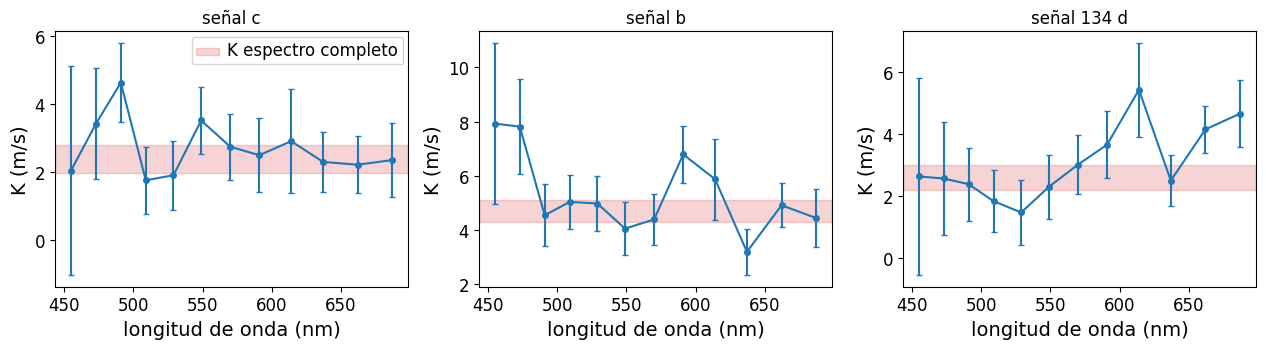

In [41]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(1, len(etiquetas), figsize=(4.3 * len(etiquetas), 3.6), sharex=True)
ax = np.atleast_1d(ax)
for j, et in enumerate(etiquetas):
    o = np.argsort(lam)
    ax[j].errorbar(lam[o], Kb_[o, j], eKb_[o, j], fmt="o-", ms=4, capsize=2)
    ax[j].axhspan(K_full[j] - eK_full[j], K_full[j] + eK_full[j], color="C3", alpha=0.2, label="K espectro completo")
    ax[j].set_title(f"señal {et}")
    ax[j].set_xlabel("longitud de onda (nm)" if usa_nm else "banda")
    ax[j].set_ylabel("K (m/s)")
ax[0].legend(fontsize=8)
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "cromaticidad_K_por_banda.png", dpi=140)
plt.show()

## Curvas de RV plegadas

Curvas de velocidad radial de b y c plegadas con su periodo, usando los tiempos de transito de Cadieux et al. 2024 (Tabla D1). Para cada planeta se resta la señal del otro y se pliega promediando en bins de fase.

In [42]:
N_BINS = 8
SVRAD_MAX_FIG = None # p. ej. 2.0 -> el grafico muestra solo las noches con error <= 2 m/s (el AJUSTE usa todas)
T_TRANSITO = {p: T0_BTJD[p] + 2457000.0 for p in ("b", "c")} # BJD (del bloque de constantes)

nombres = list(P_PLANETAS.keys())
tt = t - t0
# se rehace el ajuste aqui para no depender de variables que otras celdas reutilizan (coef, K, chi2r)
cf, _, Kf, eKf, chi2f = ajuste_sinusoides(t, y, dy, periodos, t0)
escala = np.sqrt(max(1.0, chi2f)) # ruido extra (actividad): se escalan los errores de los bins

### Figura de las curvas plegadas
Para cada planeta se resta la senal del otro, se pliega con su periodo con fase 0 en el transito y se promedia en bins de fase.

b: RV del modelo en el transito = +0.58 m/s (esperado cerca de 0); la curva va bajando (esperado: bajando)
c: RV del modelo en el transito = -0.08 m/s (esperado cerca de 0); la curva va bajando (esperado: bajando)


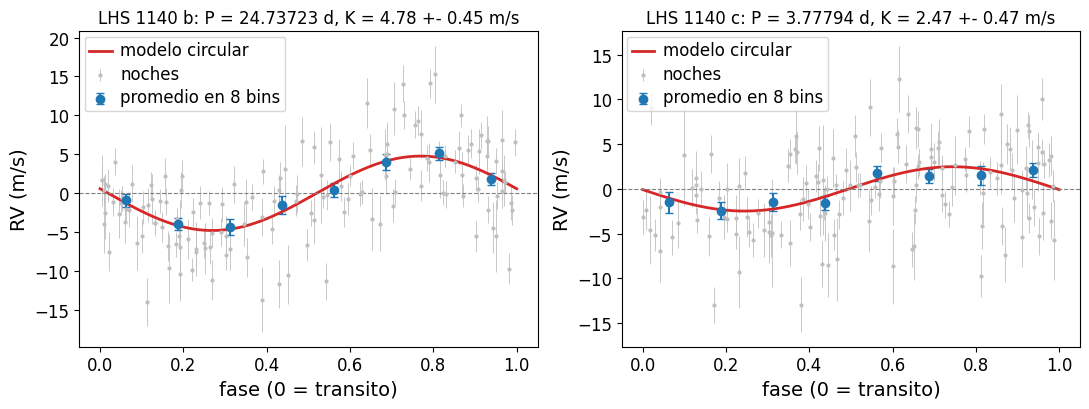

In [43]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, nombre, j in zip(ax, ["b", "c"], [1, 0]): # j: posicion del planeta en periodos (c va primero)
    P = periodos[j]
    otro = 1 - j
    mod_otro = (cf[1 + 2*otro] * np.sin(2*np.pi*tt/periodos[otro])
                + cf[2 + 2*otro] * np.cos(2*np.pi*tt/periodos[otro]))
    yy = y - cf[0] - mod_otro # RV con el otro planeta restado

    f0 = (T_TRANSITO[nombre] - t0) / P # fase 0 = transito
    fase = (tt / P - f0) % 1
    ok = np.ones(len(t), dtype=bool) if SVRAD_MAX_FIG is None else (dy <= SVRAD_MAX_FIG)

    # promedios ponderados por bin de fase
    xc, xm, xe = [], [], []
    for k in range(N_BINS):
        m = ok & (fase >= k / N_BINS) & (fase < (k + 1) / N_BINS)
        if m.sum() < 3:
            continue
        w = 1 / dy[m]**2
        xc.append((k + 0.5) / N_BINS)
        xm.append(np.sum(w * yy[m]) / np.sum(w))
        xe.append(escala / np.sqrt(np.sum(w)))

    ff = np.linspace(0, 1, 300)
    modelo = (cf[1 + 2*j] * np.sin(2*np.pi*(ff + f0)) + cf[2 + 2*j] * np.cos(2*np.pi*(ff + f0)))

    a.errorbar(fase[ok], yy[ok], dy[ok], fmt=".", color="0.75", ms=4, elinewidth=0.6, label="noches")
    a.errorbar(xc, xm, xe, fmt="o", color="C0", ms=6, capsize=3, label=f"promedio en {N_BINS} bins")
    a.plot(ff, modelo, color="C3", lw=2, label="modelo circular")
    a.axhline(0, color="gray", ls="--", lw=0.8)
    a.set_title(f"LHS 1140 {nombre}: P = {P} d, K = {Kf[j]:.2f} +- {eKf[j]:.2f} m/s")
    a.set_xlabel("fase (0 = transito)")
    a.set_ylabel("RV (m/s)")
    a.legend(fontsize=8)

    # control: con orbita circular, en el transito la RV de la estrella cruza cero bajando
    m0 = modelo[0]
    pend = modelo[1] - modelo[0]
    if pend < 0:
        sentido = "bajando"
    else:
        sentido = "subiendo"
    print(f"{nombre}: RV del modelo en el transito = {m0:+.2f} m/s (esperado cerca de 0); la curva va {sentido} (esperado: bajando)")
letra_grande(fig)
plt.tight_layout()
plt.savefig(OUT / "curva_RV_final.png", dpi=150)
plt.show()

## Referencias

Siglas usadas en las tablas: D17 = Dittmann et al. (2017), M19 = Ment et al. (2019), LB20 = Lillo-Box et al. (2020), C24 = Cadieux et al. (2024).

- Cadieux et al. (2024), **New Mass and Radius Constraints on the LHS 1140 Planets: LHS 1140 b Is Either a Temperate Mini-Neptune or a Water World**, ApJL, 960, L3, arXiv:2310.15490.
- Dittmann, J. A. et al. (2017), **A temperate rocky super-Earth transiting a nearby cool star**, Nature, 544, 333.
- Ment, K. et al. (2019), **A Second Terrestrial Planet Orbiting the Nearby M Dwarf LHS 1140**, AJ, 157, 32.
- Lillo-Box, J. et al. (2020), **Planetary system LHS 1140 revisited with ESPRESSO and TESS**, A&A, 642, A121.
- Artigau, E. et al. (2022), **Line-by-Line Velocity Measurements: an Outlier-resistant Method for Precision Velocimetry**, AJ, 164, 84.
- Mayor, M. et al. (2003), **Setting New Standards with HARPS**, The Messenger, 114, 20.
- Zechmeister, M. & Kurster, M. (2009), **The generalised Lomb-Scargle periodogram**, A&A, 496, 577.
- Datos: espectros de HARPS del ESO Science Archive Facility (https://archive.eso.org).